<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/10-sequence-classification-lstm/sequence_classification_with_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell 1 - Project plan and configuration

In [ ]:
# ============================================================
# PROJECT 10: SEQUENCE CLASSIFICATION WITH LSTM
# ============================================================
# Objective:
# Build an LSTM-based model to classify movie reviews as
# Positive or Negative using the IMDb dataset.
#
# PROJECT PLAN
# 1. Initialize the environment and random seeds.
# 2. Load the IMDb dataset.
# 3. Inspect the dataset and class distribution.
# 4. Prepare training, validation, and test sets.
# 5. Pad review sequences to a fixed length.
# 6. Build an Embedding + LSTM neural network.
# 7. Train with early stopping and best-weight restoration.
# 8. Evaluate on the held-out test set.
# 9. Calculate accuracy, precision, recall, and F1-score.
# 10. Generate a classification report and confusion matrix.
# 11. Plot training/validation curves.
# 12. Test the model on custom movie reviews.
# 13. Export metrics, predictions, plots, and model files.
# 14. Prepare evidence for the GitHub README.
#
# Dataset: IMDb movie reviews (binary sentiment)
# Model: Embedding + LSTM + Dropout + Dense
# Seed: 42
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_NAME = "Project 10: Sequence Classification with LSTM"
OUTPUT_DIR = "project10_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 60)
print(PROJECT_NAME)
print("=" * 60)
print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Output directory:", OUTPUT_DIR)
print("\nProject plan loaded successfully.")

Project 10: Sequence Classification with LSTM
TensorFlow version: 2.21.0
GPU available: False
GPU devices: []
Output directory: project10_outputs

Project plan loaded successfully.


### Cell 2 - Import libraries and evaluation metrics

In [ ]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    Dense,
    Dropout,
    SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All required libraries imported successfully.")

All required libraries imported successfully.


### Cell 3 - Configuration

In [ ]:
# Dataset and model configuration

VOCAB_SIZE = 20000
MAX_LENGTH = 250
EMBEDDING_DIM = 128

LSTM_UNITS = 64
DROPOUT_RATE = 0.4

BATCH_SIZE = 128
EPOCHS = 10
VALIDATION_SIZE = 0.20

print("Vocabulary size:", VOCAB_SIZE)
print("Maximum sequence length:", MAX_LENGTH)
print("Embedding dimensions:", EMBEDDING_DIM)
print("LSTM units:", LSTM_UNITS)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)

Vocabulary size: 20000
Maximum sequence length: 250
Embedding dimensions: 128
LSTM units: 64
Batch size: 128
Maximum epochs: 10


### Cell 4 - Load IMDb dataset

In [ ]:
# Keep only the most frequent VOCAB_SIZE words.
# The default IMDb dataset uses index 0 for padding
# and reserves indices 0-3 for special tokens.

(x_train_full, y_train_full), (x_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

y_train_full = np.asarray(y_train_full)
y_test = np.asarray(y_test)

print("Dataset loaded successfully.")
print("-" * 50)
print("Original training samples:", len(x_train_full))
print("Test samples:", len(x_test))
print("Training label shape:", y_train_full.shape)
print("Test label shape:", y_test.shape)
print("Training classes:", np.unique(y_train_full))
print("Test classes:", np.unique(y_test))

Dataset loaded successfully.
--------------------------------------------------
Original training samples: 25000
Test samples: 25000
Training label shape: (25000,)
Test label shape: (25000,)
Training classes: [0 1]
Test classes: [0 1]


### Cell 5 - Inspect class distribution

,Class,Train Count,Test Count
0,Negative,12500,12500
1,Positive,12500,12500


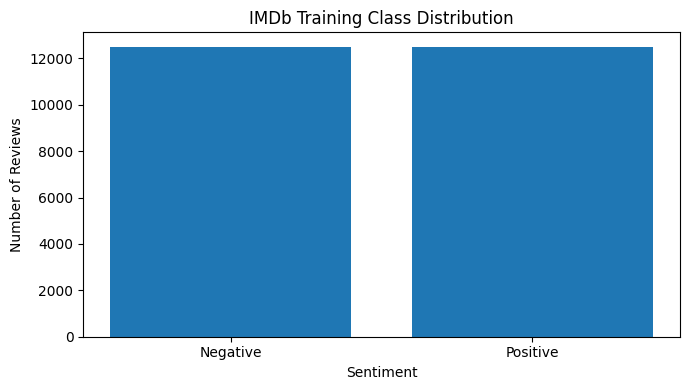

In [ ]:
class_names = {0: "Negative", 1: "Positive"}

train_distribution = pd.Series(y_train_full).value_counts().sort_index()
test_distribution = pd.Series(y_test).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Class": ["Negative", "Positive"],
    "Train Count": [
        int(train_distribution.get(0, 0)),
        int(train_distribution.get(1, 0))
    ],
    "Test Count": [
        int(test_distribution.get(0, 0)),
        int(test_distribution.get(1, 0))
    ]
})

display(distribution_df)

distribution_df.to_csv(
    os.path.join(OUTPUT_DIR, "class_distribution.csv"),
    index=False
)

plt.figure(figsize=(7, 4))
plt.bar(
    distribution_df["Class"],
    distribution_df["Train Count"]
)
plt.title("IMDb Training Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "class_distribution.png"),
    dpi=150
)
plt.show()

### Cell 6 - Review sequence length analysis

,Statistic,Words/Token IDs
0,Minimum,11.00
1,25th percentile,130.00
2,Median,178.00
3,75th percentile,291.00
4,95th percentile,610.00
5,Maximum,2494.00
6,Mean,238.71


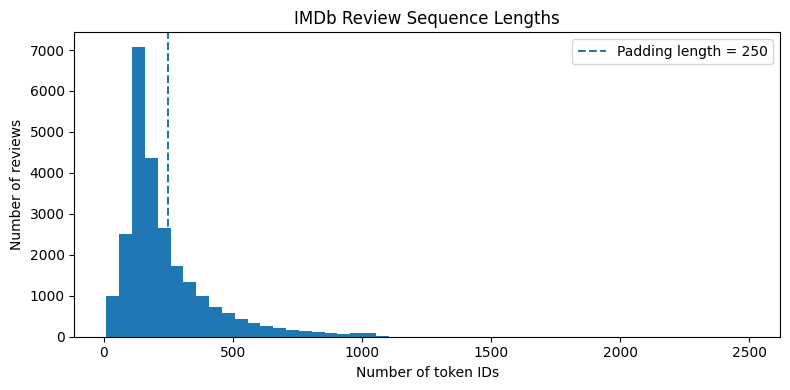

In [ ]:
sequence_lengths = np.array([len(seq) for seq in x_train_full])

length_summary = pd.DataFrame({
    "Statistic": [
        "Minimum",
        "25th percentile",
        "Median",
        "75th percentile",
        "95th percentile",
        "Maximum",
        "Mean"
    ],
    "Words/Token IDs": [
        int(np.min(sequence_lengths)),
        int(np.percentile(sequence_lengths, 25)),
        int(np.median(sequence_lengths)),
        int(np.percentile(sequence_lengths, 75)),
        int(np.percentile(sequence_lengths, 95)),
        int(np.max(sequence_lengths)),
        round(float(np.mean(sequence_lengths)), 2)
    ]
})

display(length_summary)

plt.figure(figsize=(8, 4))
plt.hist(sequence_lengths, bins=50)
plt.axvline(
    MAX_LENGTH,
    linestyle="--",
    label=f"Padding length = {MAX_LENGTH}"
)
plt.title("IMDb Review Sequence Lengths")
plt.xlabel("Number of token IDs")
plt.ylabel("Number of reviews")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "sequence_length_distribution.png"),
    dpi=150
)
plt.show()

### Cell 7 - Create training and validation sets

In [ ]:
# Split only the original training data.
# The official test set remains untouched until final evaluation.

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=y_train_full
)

print("Training samples:", len(x_train))
print("Validation samples:", len(x_val))
print("Test samples:", len(x_test))

print("\nTraining positive ratio:", round(float(y_train.mean()), 4))
print("Validation positive ratio:", round(float(y_val.mean()), 4))
print("Test positive ratio:", round(float(y_test.mean()), 4))

Training samples: 20000
Validation samples: 5000
Test samples: 25000

Training positive ratio: 0.5
Validation positive ratio: 0.5
Test positive ratio: 0.5


### Cell 8 - Pad sequences

In [ ]:
# Pad or truncate reviews to the same length.
# Pre-padding and pre-truncation are used consistently.

x_train_pad = pad_sequences(
    x_train,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre"
)

x_val_pad = pad_sequences(
    x_val,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre"
)

x_test_pad = pad_sequences(
    x_test,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre"
)

print("Padded sequence shapes:")
print("Train:", x_train_pad.shape)
print("Validation:", x_val_pad.shape)
print("Test:", x_test_pad.shape)

print("\nData type:", x_train_pad.dtype)
print("Minimum token ID:", int(x_train_pad.min()))
print("Maximum token ID:", int(x_train_pad.max()))

Padded sequence shapes:
Train: (20000, 250)
Validation: (5000, 250)
Test: (25000, 250)

Data type: int32
Minimum token ID: 0
Maximum token ID: 19999


Cell 9 - Build LSTM model

In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="word_embedding"
    ),
    SpatialDropout1D(
        DROPOUT_RATE,
        name="embedding_dropout"
    ),
    LSTM(
        LSTM_UNITS,
        dropout=0.2,
        recurrent_dropout=0.0,
        name="lstm_layer"
    ),
    Dropout(
        DROPOUT_RATE,
        name="classifier_dropout"
    ),
    Dense(
        1,
        activation="sigmoid",
        name="sentiment_output"
    )
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_dropout               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_layer (LSTM)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment_output (Dense)        │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Cell 10 - Configure callbacks

In [ ]:
checkpoint_path = os.path.join(
    OUTPUT_DIR,
    "best_lstm_model.keras"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint
]

print("Early stopping configured.")
print("Best-model checkpoint:", checkpoint_path)

Early stopping configured.
Best-model checkpoint: project10_outputs/best_lstm_model.keras


Cell 11 - Train the LSTM model

In [ ]:
history = model.fit(
    x_train_pad,
    y_train,
    validation_data=(x_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

history_df = pd.DataFrame(history.history)
history_df.insert(
    0,
    "epoch",
    np.arange(1, len(history_df) + 1)
)

history_df.to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

print("\nTraining completed.")
print("Epochs actually run:", len(history.history["loss"]))
print("Best validation loss:", round(
    float(min(history.history["val_loss"])), 4
))

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 629ms/step - accuracy: 0.6914 - loss: 0.5663
Epoch 1: val_loss improved from None to 0.32263, saving model to project10_outputs/best_lstm_model.keras

Epoch 1: finished saving model to project10_outputs/best_lstm_model.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 112s 698ms/step - accuracy: 0.7839 - loss: 0.4571 - val_accuracy: 0.8700 - val_loss: 0.3226
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - accuracy: 0.8959 - loss: 0.2684
Epoch 2: val_loss did not improve from 0.32263
157/157 ━━━━━━━━━━━━━━━━━━━━ 138s 671ms/step - accuracy: 0.9050 - loss: 0.2484 - val_accuracy: 0.8506 - val_loss: 0.3488
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - accuracy: 0.9293 - loss: 0.1981
Epoch 3: val_loss did not improve from 0.32263
157/157 ━━━━━━━━━━━━━━━━━━━━ 107s 681ms/step - accuracy: 0.9225 - loss: 0.2089 - val_accuracy: 0.8692 - val_loss: 0.3313
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.

Training comple

### Cell 12 - Plot training and validation curves

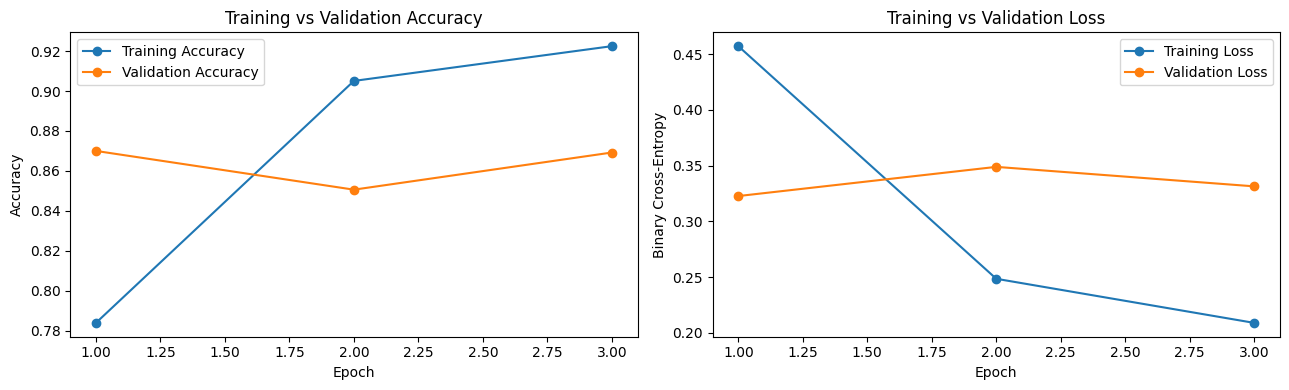

In [ ]:
epochs_ran = range(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    epochs_ran,
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[0].plot(
    epochs_ran,
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    epochs_ran,
    history.history["loss"],
    marker="o",
    label="Training Loss"
)
axes[1].plot(
    epochs_ran,
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "training_curves.png"),
    dpi=150
)
plt.show()

### Cell 13 - Evaluate on the held-out test set

In [ ]:
test_loss, test_accuracy_keras = model.evaluate(
    x_test_pad,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

y_prob = model.predict(
    x_test_pad,
    batch_size=BATCH_SIZE,
    verbose=1
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(
    y_test, y_pred, zero_division=0
)
test_recall = recall_score(
    y_test, y_pred, zero_division=0
)
test_f1 = f1_score(
    y_test, y_pred, zero_division=0
)

metrics_df = pd.DataFrame([{
    "model": "Embedding + LSTM",
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "threshold": 0.5,
    "test_samples": int(len(y_test))
}])

display(metrics_df.round(4))

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_metrics.csv"),
    index=False
)

196/196 ━━━━━━━━━━━━━━━━━━━━ 35s 179ms/step - accuracy: 0.8605 - loss: 0.3333
196/196 ━━━━━━━━━━━━━━━━━━━━ 36s 183ms/step


,model,test_loss,test_accuracy,test_precision,test_recall,test_f1,threshold,test_samples
0,Embedding + LSTM,0.3333,0.8605,0.9118,0.7982,0.8513,0.5,25000


### Cell 14 - Classification report

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import os

print("Generating classification report...")

report_dict = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df.round(4))

report_df.to_csv(
    os.path.join(OUTPUT_DIR, "classification_report.csv")
)

print("Cell 14 completed successfully.")

Generating classification report...


,precision,recall,f1-score,support
Negative,0.8206,0.9228,0.8687,12500.0000
Positive,0.9118,0.7982,0.8513,12500.0000
accuracy,0.8605,0.8605,0.8605,0.8605
macro avg,0.8662,0.8605,0.8600,25000.0000
weighted avg,0.8662,0.8605,0.8600,25000.0000


Cell 14 completed successfully.


### Cell 15 - Confusion matrix

Generating confusion matrix...
[[11535   965]
 [ 2522  9978]]


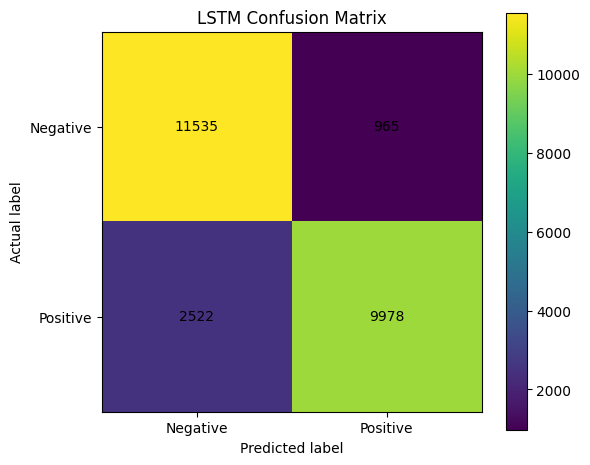

Cell 15 completed successfully.


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import os

print("Generating confusion matrix...")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    xlabel="Predicted label",
    ylabel="Actual label",
    title="LSTM Confusion Matrix"
)

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")

fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=150
)
plt.show()
plt.close(fig)

print("Cell 15 completed successfully.")

### Cell 16 — Inspect misclassified examples

In [ ]:
misclassified_indices = np.flatnonzero(y_test != y_pred)

print("Misclassified test reviews:", len(misclassified_indices))
print("Total test reviews:", len(y_test))

# The IMDb dataset stores reviews as token IDs.
# The following code decodes IDs back into readable words.

word_index = imdb.get_word_index()

index_word = {
    index + 3: word
    for word, index in word_index.items()
}
index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNK>"
index_word[3] = "<UNUSED>"

def decode_review(sequence):
    return " ".join(
        index_word.get(int(token), "?")
        for token in sequence
        if int(token) > 3
    )

error_rows = []

for idx in misclassified_indices[:10]:
    error_rows.append({
        "actual": class_names[int(y_test[idx])],
        "predicted": class_names[int(y_pred[idx])],
        "predicted_positive_probability": float(y_prob[idx]),
        "review_excerpt": decode_review(x_test[idx])[:500]
    })

errors_df = pd.DataFrame(error_rows)
display(errors_df)

errors_df.to_csv(
    os.path.join(OUTPUT_DIR, "misclassified_examples.csv"),
    index=False
)

Misclassified test reviews: 3487
Total test reviews: 25000


,actual,predicted,predicted_positive_probability,review_excerpt
0,Positive,Negative,0.347624,many animation buffs consider the great forgot...
1,Negative,Positive,0.901416,hollywood had a long love affair with bogus ar...
2,Positive,Negative,0.169786,how managed to avoid attention remains a myste...
3,Negative,Positive,0.764057,if you have never read the classic science fic...
4,Positive,Negative,0.393564,i saw this 1997 movie because i am a fan of lo...
5,Positive,Negative,0.217873,i can't understand why imdb users would rate t...
6,Negative,Positive,0.590705,oh how awfully this movie is i don't know if i...
7,Positive,Negative,0.281473,alice is the kind of movie they made in the 30...
8,Positive,Negative,0.051731,with the obvious exception of fools horses thi...
9,Positive,Negative,0.294005,okay i know that's cliché taken on its surface...


### Cell 17 - Predict custom reviews

In [ ]:
def predict_sentiment(review, model=model):
    """
    Predict sentiment for a new English movie review.

    Returns the predicted class and model score.
    The score is the model's sigmoid output, not a guarantee
    of real-world correctness.
    """
    encoded = imdb_tokenize(review)

    padded = pad_sequences(
        [encoded],
        maxlen=MAX_LENGTH,
        padding="pre",
        truncating="pre"
    )

    positive_score = float(
        model.predict(padded, verbose=0)[0][0]
    )

    label = "Positive" if positive_score >= 0.5 else "Negative"

    return {
        "review": review,
        "predicted_sentiment": label,
        "positive_class_score": round(positive_score, 4)
    }


def imdb_tokenize(text):
    # Use the IMDb training vocabulary.
    # Index 1 is the start token; index 2 is unknown.
    words = text.lower().split()
    encoded = [1]

    for word in words:
        idx = word_index.get(word)

        if idx is None:
            encoded.append(2)
        else:
            encoded.append(idx + 3 if idx + 3 < VOCAB_SIZE else 2)

    return encoded


custom_reviews = [
    "This movie was wonderful and the acting was excellent.",
    "The film was boring and the story was terrible.",
    "I enjoyed the performances and would watch it again.",
    "The plot was confusing and I did not like this movie."
]

custom_results = pd.DataFrame([
    predict_sentiment(review)
    for review in custom_reviews
])

display(custom_results)

custom_results.to_csv(
    os.path.join(OUTPUT_DIR, "custom_predictions.csv"),
    index=False
)

,review,predicted_sentiment,positive_class_score
0,This movie was wonderful and the acting was ex...,Positive,0.5983
1,The film was boring and the story was terrible.,Negative,0.3118
2,I enjoyed the performances and would watch it ...,Positive,0.6890
3,The plot was confusing and I did not like this...,Negative,0.2207


### Cell 18 - Save the final model

In [ ]:
final_model_path = os.path.join(
    OUTPUT_DIR,
    "final_lstm_model.keras"
)

model.save(final_model_path)

print("Final model saved to:", final_model_path)
print("Best checkpoint exists:", os.path.exists(checkpoint_path))
print("Final model exists:", os.path.exists(final_model_path))

Final model saved to: project10_outputs/final_lstm_model.keras
Best checkpoint exists: True
Final model exists: True


### Cell 19 - Export test predictions

In [ ]:
predictions_df = pd.DataFrame({
    "actual_label": y_test.astype(int),
    "predicted_label": y_pred.astype(int),
    "actual_sentiment": [
        class_names[int(v)] for v in y_test
    ],
    "predicted_sentiment": [
        class_names[int(v)] for v in y_pred
    ],
    "positive_class_score": y_prob.astype(float)
})

predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

display(predictions_df.head(10))

print("Test predictions exported.")

,actual_label,predicted_label,actual_sentiment,predicted_sentiment,positive_class_score
0,0,0,Negative,Negative,0.117760
1,1,1,Positive,Positive,0.936010
2,1,0,Positive,Negative,0.347624
3,0,0,Negative,Negative,0.050252
4,1,1,Positive,Positive,0.978157
5,1,1,Positive,Positive,0.833886
6,1,1,Positive,Positive,0.784645
7,0,0,Negative,Negative,0.066163
8,0,1,Negative,Positive,0.901416
9,1,1,Positive,Positive,0.884545


Test predictions exported.


### Cell 20 - Save project summary

In [ ]:
best_epoch = int(
    np.argmin(history.history["val_loss"]) + 1
)

summary = {
    "project": PROJECT_NAME,
    "dataset": "IMDb Movie Reviews",
    "task": "Binary sentiment classification",
    "seed": SEED,
    "vocabulary_size": VOCAB_SIZE,
    "max_sequence_length": MAX_LENGTH,
    "embedding_dimensions": EMBEDDING_DIM,
    "lstm_units": LSTM_UNITS,
    "train_samples": int(len(x_train)),
    "validation_samples": int(len(x_val)),
    "test_samples": int(len(x_test)),
    "epochs_run": int(len(history.history["loss"])),
    "best_validation_loss_epoch": best_epoch,
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "output_files": sorted(os.listdir(OUTPUT_DIR))
}

summary_path = os.path.join(
    OUTPUT_DIR,
    "project_summary.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "project": "Project 10: Sequence Classification with LSTM",
  "dataset": "IMDb Movie Reviews",
  "task": "Binary sentiment classification",
  "seed": 42,
  "vocabulary_size": 20000,
  "max_sequence_length": 250,
  "embedding_dimensions": 128,
  "lstm_units": 64,
  "train_samples": 20000,
  "validation_samples": 5000,
  "test_samples": 25000,
  "epochs_run": 3,
  "best_validation_loss_epoch": 1,
  "test_loss": 0.33332473039627075,
  "test_accuracy": 0.86052,
  "test_precision": 0.9118157726400439,
  "test_recall": 0.79824,
  "test_f1": 0.8512562385360235,
  "output_files": [
    "best_lstm_model.keras",
    "class_distribution.csv",
    "class_distribution.png",
    "classification_report.csv",
    "confusion_matrix.png",
    "custom_predictions.csv",
    "final_lstm_model.keras",
    "misclassified_examples.csv",
    "project_summary.json",
    "sequence_length_distribution.png",
    "test_metrics.csv",
    "test_predictions.csv",
    "training_curves.png",
    "training_history.cs

### Cell 21 - Verify all output files

In [ ]:
print("PROJECT 10 — OUTPUT FILE CHECK")
print("=" * 60)

for filename in sorted(os.listdir(OUTPUT_DIR)):
    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"{filename:40s} {size_kb:8.2f} KB")

print("\nAll available outputs are listed above.")

PROJECT 10 — OUTPUT FILE CHECK
best_lstm_model.keras                    30611.08 KB
class_distribution.csv                       0.07 KB
class_distribution.png                      32.34 KB
classification_report.csv                    0.32 KB
confusion_matrix.png                        43.71 KB
custom_predictions.csv                       0.31 KB
final_lstm_model.keras                   30611.08 KB
misclassified_examples.csv                   5.32 KB
project_summary.json                         0.98 KB
sequence_length_distribution.png            39.28 KB
test_metrics.csv                             0.18 KB
test_predictions.csv                      1014.42 KB
training_curves.png                         91.55 KB
training_history.csv                         0.27 KB

All available outputs are listed above.


### Cell 22 - Download output ZIP

In [ ]:
import shutil

zip_path = shutil.make_archive(
    "project10_outputs",
    "zip",
    OUTPUT_DIR
)

print("ZIP created:", zip_path)

from google.colab import files
files.download(zip_path)

ZIP created: /content/project10_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>